# iAmTime forecasting demo on economic data

[iAmTime](https://arxiv.org/abs/2603.22586) is a time-series foundation model that accepts **in-context examples**: completed (history → future) demonstrations passed together with the series to forecast. This notebook is the economics counterpart of `iamtime_walmart_forecasting_demo.ipynb` and `iamtime_energy_forecasting_demo.ipynb`. It uses public economic datasets from [fev-bench](https://huggingface.co/spaces/autogluon/fev-bench) (`autogluon/fev_datasets`) and keeps the same three-part format per section:

| Part | What you get |
|---|---|
| **Input card** | the exact array / dict shape passed to `predict_quantiles` |
| **Hero figure** | history → forecast fan (10–90 %) + median, observed future overlaid, and one **dashed reference line** = "what you would get without the feature" |
| **Honesty table** | the same comparison on many series or forecast origins: mean / median MASE, win rate, paired bootstrap CI |

| § | Task | fev-bench dataset | Horizon | Reference line | Why this dataset |
|---|---|---|---|---|---|
| 1 | Univariate forecasting | `us_consumption_1M`: US personal consumption expenditures, 31 categories, monthly 1959–2024 | 12 months | random walk with drift | long, seasonally adjusted series with trends, recessions and the COVID shock |
| 2 | Multivariate forecasting | `fred_md_2025`: the fev-bench `cee` task, payrolls (`PAYEMS`), CPI (`CPIAUCSL`) and the federal funds rate (`FEDFUNDS`) | 12 months | univariate forecast of the same variable | the classic monetary-policy trio, forecast jointly in fev-bench |
| 3 | Covariates and what-if scenarios | `gvar`: 33 countries, quarterly 1979–2023; inflation `Dp` with global commodity prices (oil, raw materials, metals) | 8 quarters | forecast without covariates | the fev-bench `gvar` task uses these commodity prices as **past-only** covariates; their future paths are natural scenario inputs |
| 4 | Forecasting with examples (ICL) | `gvar`: log real GDP `y` of 33 countries | 8 quarters | zero-shot from the same 20-quarter context | **historical analogues**: past windows from any country whose recent trajectory looks like the query's, with what happened next |

Unlike retail or energy, macro series are mostly seasonally adjusted, so examples cannot add calendar seasonality. What they can add is how similar situations unfolded before, the idea behind analogue forecasting in economics.

Other fev-bench economic datasets that fit the same workflows: `fred_qd_2025` (quarterly version of FRED-MD, 246 series), `us_consumption_1Q/1Y`, and annual country panels (`world_co2_emissions`, `world_tourism`, `world_life_expectancy`, 5-year horizon) for univariate and cross-country analogue examples.

Checkpoint: [`anishsaha/iAmTime-base-forecast`](https://huggingface.co/anishsaha/iAmTime-base-forecast). Figures are saved to `docs/figures/` (relative to the notebook).

## Setup

Install the package with the notebook and training extras from the repository root (the `training` extra provides `datasets` and `pandas`):

```bash
pip install -e ".[notebook,training]"
```

The first run downloads the checkpoint and the datasets from the Hugging Face Hub and caches them locally.

In [1]:
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from matplotlib.ticker import FuncFormatter

from iAmTime.pipeline import iAmTimePipeline

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=3, suppress=True)

In [2]:
if torch.cuda.is_available():
    DEVICE = "cuda"
    TORCH_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32
else:
    DEVICE = "cpu"
    TORCH_DTYPE = torch.float32

MODEL_ID = "anishsaha/iAmTime-base-forecast"

print(f"Device: {DEVICE}")
print(f"Dtype: {TORCH_DTYPE}")
print(f"Model: {MODEL_ID}")

Device: cpu
Dtype: torch.float32
Model: anishsaha/iAmTime-base-forecast


In [3]:
pipeline = iAmTimePipeline.from_pretrained(
    MODEL_ID,
    device_map=DEVICE,
    dtype=TORCH_DTYPE,
)
pipeline.model.eval()
print("Pipeline loaded successfully.")

Pipeline loaded successfully.


### Helpers: data, forecasts, evaluation, plots

Every dataset is loaded with the same helper: one row per item, with the target and covariates as equal-length arrays. Gaps are filled by linear interpolation.

Forecasts are scored with **MASE**: the mean absolute error of the median forecast divided by the in-sample mean absolute error of a one-step naive forecast on the context (season 1, as fev-bench uses for macro data). Because macro series trend and the horizon is 8–12 steps, MASE values above 1 are normal here; compare variants, not absolute levels. Each section ends with a **scorecard**: mean and median MASE, the win rate against a reference variant, and a paired bootstrap 95 % CI on the mean difference.

In [4]:
DATASET_PATH = "autogluon/fev_datasets"
QUANTILE_LEVELS = [0.1, 0.5, 0.9]
COLORS = {"history": "#3f4652", "truth": "#23836b", "forecast": "#8f5fa2", "reference": "#d08c2e"}

FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"econ_{name}.png", dpi=130, bbox_inches="tight")

def load_config(config):
    return load_dataset(DATASET_PATH, config, split="train").to_pandas()

def column_matrix(frame, column):
    matrix = np.stack([np.asarray(values, dtype=np.float64) for values in frame[column]])
    return pd.DataFrame(matrix.T).interpolate(limit_direction="both").to_numpy().T.astype(np.float32)

def predict(input_batch, horizon):
    quantiles, _ = pipeline.predict_quantiles(input_batch, prediction_length=horizon, quantile_levels=QUANTILE_LEVELS)
    return quantiles.detach().cpu().numpy() if isinstance(quantiles, torch.Tensor) else quantiles

def mase(history, truth, forecast, season):
    scale = np.mean(np.abs(history[season:] - history[:-season]))
    return float(np.mean(np.abs(truth - forecast)) / max(scale, 1e-6))

def seasonal_naive(history, horizon, season):
    return np.resize(history[-season:], horizon)

def scorecard(scores, reference, n_boot=2000, seed=0):
    # scores: DataFrame, one column per variant, one row per forecast, values = MASE.
    rng = np.random.default_rng(seed)
    n = len(scores)
    idx = rng.integers(0, n, size=(n_boot, n))
    ref = scores[reference].to_numpy()
    rows = []
    for name in scores.columns:
        s = scores[name].to_numpy()
        diff = s - ref
        mean_ci = np.percentile(s[idx].mean(axis=1), [2.5, 97.5])
        diff_ci = np.percentile(diff[idx].mean(axis=1), [2.5, 97.5])
        rows.append({
            "mean MASE": s.mean(), "mean 95% CI": f"[{mean_ci[0]:.3f}, {mean_ci[1]:.3f}]",
            "median MASE": np.median(s),
            "win rate vs ref": np.nan if name == reference else (s < ref).mean(),
            "Δ mean vs ref": diff.mean(), "Δ 95% CI": f"[{diff_ci[0]:.3f}, {diff_ci[1]:.3f}]",
        })
    table = pd.DataFrame(rows, index=scores.columns)
    table.index.name = f"reference: {reference}"
    return table.round(3)

def plot_ladder(scores, reference, title, name=None, n_boot=2000):
    # Horizontal bars of mean MASE with bootstrap CIs; the reference bar is grey.
    rng = np.random.default_rng(0)
    idx = rng.integers(0, len(scores), size=(n_boot, len(scores)))
    means = scores.mean()
    cis = np.stack([np.percentile(scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in scores.columns])
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(scores.columns) + 1.2))
    y = np.arange(len(scores.columns))[::-1]
    colors = ["#9a9a9a" if c == reference else COLORS["forecast"] for c in scores.columns]
    ax.barh(y, means, color=colors, height=0.6)
    ax.errorbar(means, y, xerr=[means - cis[:, 0], cis[:, 1] - means], fmt="none", ecolor="#333333", capsize=3, lw=1)
    ax.set_yticks(y, scores.columns)
    ax.set_xlabel(f"mean MASE over {len(scores)} forecasts (bootstrap 95% CI)")
    ax.set_title(title)
    ax.axvline(means[reference], color="#9a9a9a", lw=0.8, ls="--")
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

def plot_forecast(ax, history_x, history, future_x, truth, quantiles, title, reference=None, reference_label=None, ylabel=None):
    ax.plot(history_x, history, color=COLORS["history"], lw=1.1, label="History")
    ax.plot(future_x, truth, color=COLORS["truth"], lw=1.3, label="Observed future")
    ax.fill_between(future_x, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.20, label="10-90% interval")
    ax.plot(future_x, quantiles[:, 1], color=COLORS["forecast"], lw=1.6, label="Median forecast")
    if reference is not None:
        ax.plot(future_x, reference, color=COLORS["reference"], lw=1.2, ls="--", label=reference_label)
    ax.axvline(future_x[0], color="#999999", lw=0.8, ls="--")
    ax.set_title(title)
    if ylabel:
        ax.set_ylabel(ylabel)

def random_walk_drift(history, horizon):
    # The standard macro benchmark: last value plus the average historical change per step.
    drift = np.mean(np.diff(history))
    return history[-1] + drift * np.arange(1, horizon + 1)

## 1. Univariate forecasting: US consumer spending

**Data.** `us_consumption_1M`: monthly personal consumption expenditures for 31 categories (and the total), 1959–2024, seasonally adjusted.

**Input card.** A two-dimensional array with shape `(batch, context)`:

```python
uni_input = consumption[rows, origin - 120:origin]      # (3, 120): 10 years of monthly data
quantiles, _ = pipeline.predict_quantiles(uni_input, prediction_length=12, quantile_levels=[0.1, 0.5, 0.9])
# quantiles: (3, 12, 3)
```

The batch holds three categories with different behaviour: total spending (smooth growth), gasoline and other energy goods (price-driven swings), and information-processing equipment (strong trend). The forecast covers the last 12 months of the data (2024).

**How to read the figure.** Grey = the last five years of the context; purple = median forecast with the 10–90 % band; green = what actually happened; **dashed orange = random walk with drift**, the standard benchmark in macro forecasting. MASE of both in each title.

31 categories; 1959-01-01 to 2024-12-01


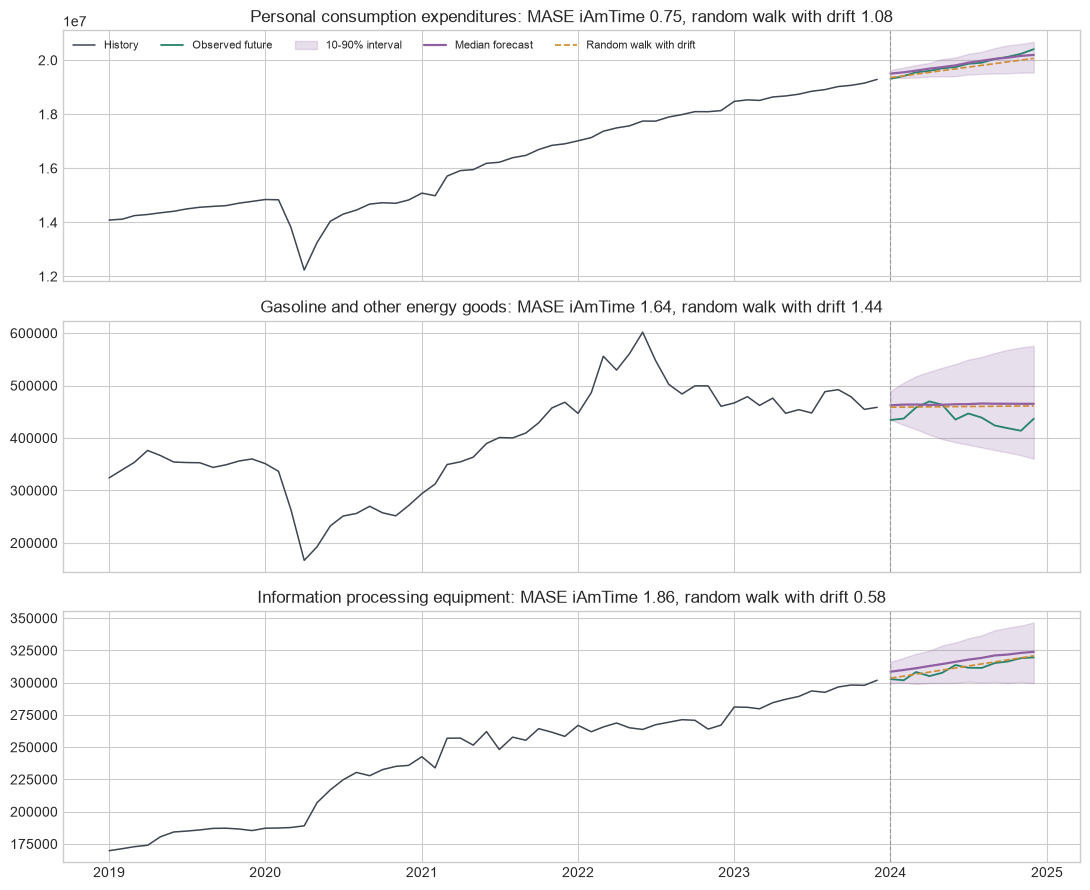

In [5]:
MONTHLY_HORIZON = 12
MONTHLY_CONTEXT = 120
CONSUMPTION_IDS = ["personal_consumption_expenditures", "gasoline_and_other_energy_goods", "information_processing_equipment"]

consumption_frame = load_config("us_consumption_1M")
consumption_ids = consumption_frame["id"].tolist()
months = pd.DatetimeIndex(consumption_frame["timestamp"].iloc[0])
consumption = column_matrix(consumption_frame, "target")
print(f"{len(consumption_ids)} categories; {months[0].date()} to {months[-1].date()}")

def pretty(name):
    return name.replace("_", " ").capitalize()

origin = len(months) - MONTHLY_HORIZON
rows = [consumption_ids.index(name) for name in CONSUMPTION_IDS]
uni_quantiles = predict(consumption[rows, origin - MONTHLY_CONTEXT:origin], MONTHLY_HORIZON)

fig, axes = plt.subplots(len(rows), 1, figsize=(11, 3.0 * len(rows)), sharex=True)
for ax, row, quantiles in zip(axes, rows, uni_quantiles):
    context = consumption[row, origin - MONTHLY_CONTEXT:origin]
    truth = consumption[row, origin:origin + MONTHLY_HORIZON]
    baseline = random_walk_drift(context, MONTHLY_HORIZON)
    plot_forecast(ax, months[origin - 60:origin], context[-60:], months[origin:origin + MONTHLY_HORIZON], truth, quantiles,
                  f"{pretty(consumption_ids[row])}: MASE iAmTime {mase(context, truth, quantiles[:, 1], 1):.2f}, random walk with drift {mase(context, truth, baseline, 1):.2f}",
                  reference=baseline, reference_label="Random walk with drift")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "01_univariate")
plt.show()

### 1b. Scorecard: iAmTime vs. random walk with drift

All 31 series, 10 yearly forecast origins (2015–2024, as in fev-bench's 10 evaluation windows), 310 twelve-month forecasts. The origins include the COVID collapse of 2020 and the rebound and inflation of 2021–2022.

In [6]:
score_origins = [len(months) - MONTHLY_HORIZON - k * 12 for k in range(10)]
score_pairs = [(row, o) for row in range(len(consumption_ids)) for o in score_origins]
score_quantiles = predict(np.stack([consumption[row, o - MONTHLY_CONTEXT:o] for row, o in score_pairs]), MONTHLY_HORIZON)

def consumption_score(row, o, forecast):
    return mase(consumption[row, o - MONTHLY_CONTEXT:o], consumption[row, o:o + MONTHLY_HORIZON], forecast, 1)

uni_scores = pd.DataFrame({
    "random walk with drift": [consumption_score(row, o, random_walk_drift(consumption[row, o - MONTHLY_CONTEXT:o], MONTHLY_HORIZON)) for row, o in score_pairs],
    "iAmTime zero-shot": [consumption_score(row, o, q[:, 1]) for (row, o), q in zip(score_pairs, score_quantiles)],
}, index=pd.MultiIndex.from_tuples([(consumption_ids[r], months[o].year) for r, o in score_pairs], names=["series", "origin year"]))
print("Mean MASE per origin year:")
print(uni_scores.groupby(level="origin year").mean().round(2).T.to_string())
scorecard(uni_scores.reset_index(drop=True), reference="random walk with drift")

Mean MASE per origin year:
origin year             2015  2016  2017  2018  2019   2020  2021  2022  2023  2024
random walk with drift  2.18  2.57  2.70  2.83  6.11  11.88  6.90  2.99  2.77  1.35
iAmTime zero-shot       2.70  2.35  2.19  2.88  4.16  11.42  6.74  2.76  2.39  1.71


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: random walk with drift,,,,,,
random walk with drift,4.228,"[3.765, 4.695]",2.588,NaN,0.000,"[0.000, 0.000]"
iAmTime zero-shot,3.930,"[3.495, 4.380]",2.434,0.568,-0.298,"[-0.493, -0.101]"


**Result.** iAmTime beats the random walk with drift on 57 % of the 310 forecasts (mean MASE 3.93 vs 4.23; the CI on the difference excludes 0). The gain comes mainly from 2016–2017 and 2019–2023, including the COVID years; in 2015, 2018 and 2024, calmer years in which spending largely kept its trend, the random walk with drift is as good or better.

## 2. Multivariate forecasting: payrolls, prices and the policy rate

**Data.** `fred_md_2025`: the FRED-MD monthly macro database (July 2025 vintage, 1959–2025, 126 series). fev-bench's `cee` task, named after the Christiano–Eichenbaum–Evans monetary VAR, forecasts nonfarm payrolls (`PAYEMS`), the consumer price index (`CPIAUCSL`) and the federal funds rate (`FEDFUNDS`) jointly.

**Input card.** A three-dimensional array with shape `(batch, variates, context)`; the output gains a variate axis:

```python
multi_input = np.stack([fred["PAYEMS"], fred["CPIAUCSL"], fred["FEDFUNDS"]])[None, :, origin - 240:origin]   # (1, 3, 240)
quantiles, _ = pipeline.predict_quantiles(multi_input, prediction_length=12, quantile_levels=[0.1, 0.5, 0.9])
# quantiles: (1, 3, 12, 3)
```

**How to read the figure.** The last 12 months of the data (mid-2024 to mid-2025). Solid purple = joint forecast; **dashed orange = the same variable forecast on its own**. The title shows both MASE values.

FRED-MD: 126 series; 1959-01-01 to 2025-06-01


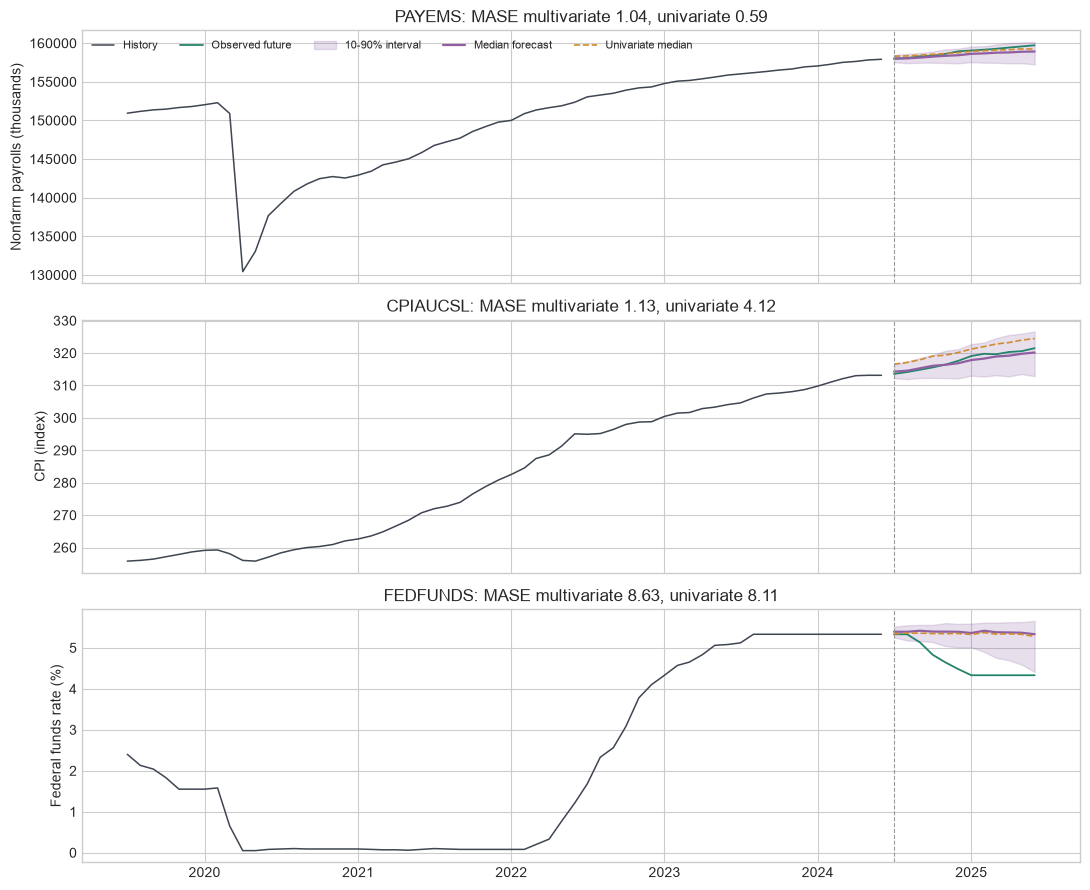

In [7]:
CEE = ["PAYEMS", "CPIAUCSL", "FEDFUNDS"]
CEE_LABELS = {"PAYEMS": "Nonfarm payrolls (thousands)", "CPIAUCSL": "CPI (index)", "FEDFUNDS": "Federal funds rate (%)"}
FRED_CONTEXT = 240

fred_frame = load_config("fred_md_2025")
fred_months = pd.DatetimeIndex(fred_frame["timestamp"].iloc[0])
fred = {name: column_matrix(fred_frame, name)[0] for name in fred_frame.columns if name not in ("id", "timestamp")}
print(f"FRED-MD: {len(fred)} series; {fred_months[0].date()} to {fred_months[-1].date()}")

origin = len(fred_months) - MONTHLY_HORIZON
cee_context = np.stack([fred[name][origin - FRED_CONTEXT:origin] for name in CEE])
joint_quantiles = predict(cee_context[None], MONTHLY_HORIZON)[0]
single_quantiles = predict(cee_context, MONTHLY_HORIZON)

fig, axes = plt.subplots(len(CEE), 1, figsize=(11, 3.0 * len(CEE)), sharex=True)
for ax, name, context, joint, single in zip(axes, CEE, cee_context, joint_quantiles, single_quantiles):
    truth = fred[name][origin:origin + MONTHLY_HORIZON]
    plot_forecast(ax, fred_months[origin - 60:origin], context[-60:], fred_months[origin:origin + MONTHLY_HORIZON], truth, joint,
                  f"{name}: MASE multivariate {mase(context, truth, joint[:, 1], 1):.2f}, univariate {mase(context, truth, single[:, 1], 1):.2f}",
                  reference=single[:, 1], reference_label="Univariate median", ylabel=CEE_LABELS[name])
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "02_multivariate")
plt.show()

### 2b. Scorecard: joint vs. separate

20 yearly forecast origins (2005–2024, matching fev-bench's 20 windows), 60 variable forecasts, each with a 20-year context.

In [8]:
cee_origins = [len(fred_months) - MONTHLY_HORIZON - k * 12 for k in range(20)]
cee_contexts = np.stack([np.stack([fred[name][o - FRED_CONTEXT:o] for name in CEE]) for o in cee_origins])          # (20, 3, 240)
cee_truths = np.stack([np.stack([fred[name][o:o + MONTHLY_HORIZON] for name in CEE]) for o in cee_origins])
joint = predict(cee_contexts, MONTHLY_HORIZON)
separate = predict(cee_contexts.reshape(-1, FRED_CONTEXT), MONTHLY_HORIZON).reshape(joint.shape)

flat = lambda a: a.reshape(-1, *a.shape[2:])
multi_scores = pd.DataFrame({
    "univariate (each variable alone)": [mase(h, y, q[:, 1], 1) for h, y, q in zip(flat(cee_contexts), flat(cee_truths), flat(separate))],
    "multivariate (joint)": [mase(h, y, q[:, 1], 1) for h, y, q in zip(flat(cee_contexts), flat(cee_truths), flat(joint))],
    "variable": CEE * len(cee_origins),
})
print("Mean MASE per variable:")
print(multi_scores.groupby("variable").mean().loc[CEE].round(3).T.to_string())
scorecard(multi_scores.drop(columns="variable"), reference="univariate (each variable alone)")

Mean MASE per variable:
variable                          PAYEMS  CPIAUCSL  FEDFUNDS
univariate (each variable alone)   5.369     5.616     4.155
multivariate (joint)               5.141     5.235     4.187


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: univariate (each variable alone),,,,,,
univariate (each variable alone),5.046,"[3.719, 6.557]",2.862,NaN,0.000,"[0.000, 0.000]"
multivariate (joint),4.854,"[3.607, 6.287]",2.787,0.467,-0.192,"[-0.595, 0.115]"


**Result.** Joint forecasting lowers the mean error a little (4.85 vs 5.05), mostly through CPI (5.24 vs 5.62) and payrolls, with the federal funds rate unchanged. It wins on only 47 % of forecasts and the CI on the difference includes 0, so the gain is not reliable. Policy-rate turns, like the 2024 cuts in the figure, are not predicted with or without the other variables.

## 3. Covariates: inflation and global commodity prices

**Data.** `gvar`: the GVAR quarterly dataset for 33 countries, 1979–2023. Per country: log real GDP (`y`), inflation (`Dp`, quarterly change in log CPI), log real equity prices (`eq`), log real exchange rate (`ep`), short and long interest rates (`r`, `lr`). Global variables: log prices of oil (`poil`), agricultural raw materials (`pmat`) and metals (`pmetal`).

fev-bench uses the commodity prices as **past-only** covariates: at forecast time you know their history but not their future. That is the realistic setting and the main comparison here. As an upper bound, the scorecard also shows the forecast with the **observed future** commodity prices, which nobody has in real time.

**Input card.** A dictionary per country. Past covariates only:

```python
{
    "target": Dp[country, origin - 60:origin],                                      # (60,): 15 years of quarterly inflation
    "past_covariates": {"poil": ..., "pmat": ..., "pmetal": ...},                   # each (60,)
}
```

With future values (oracle upper bound, or a scenario in 3b), add `"future_covariates": {"poil": ..., ...}`, each of length 8.

**How to read the figure.** US inflation from 2021Q3, the start of the 2021–2022 inflation surge. Solid = forecast with past commodity prices; **dashed = without covariates**; dotted = with the observed future commodity prices (oracle). Lower panel: the three commodity prices (log, shifted to start at 0).

GVAR: 33 countries; 1979-04-01 to 2023-07-01


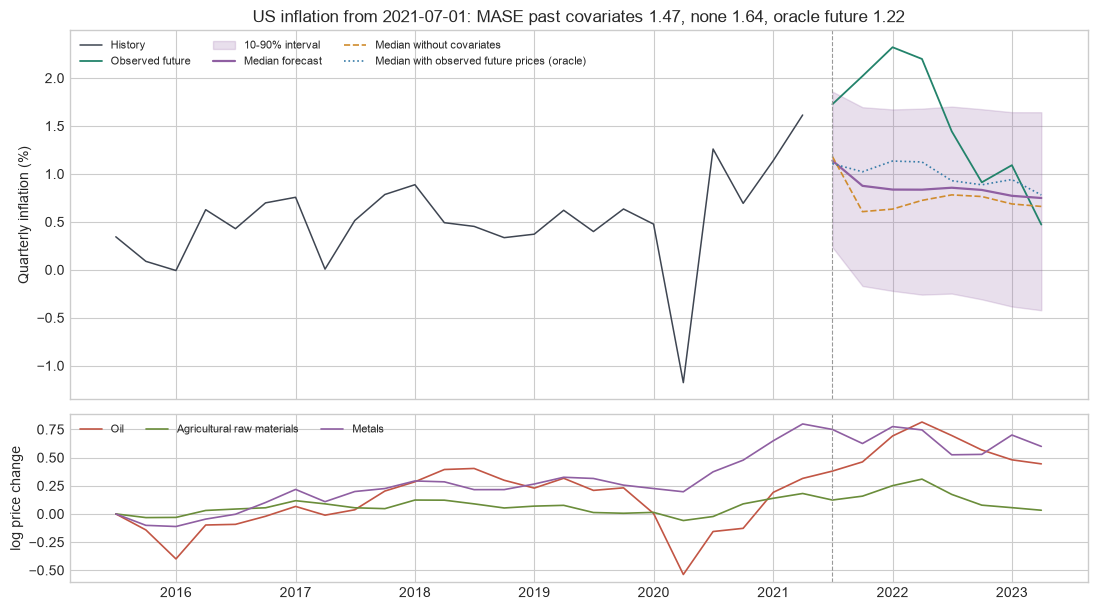

In [9]:
QUARTERLY_HORIZON = 8
GVAR_CONTEXT = 60
COMMODITIES = ["poil", "pmat", "pmetal"]
COMMODITY_LABELS = {"poil": "Oil", "pmat": "Agricultural raw materials", "pmetal": "Metals"}

gvar_frame = load_config("gvar")
countries = gvar_frame["id"].tolist()
quarters = pd.DatetimeIndex(gvar_frame["timestamp"].iloc[0])
gvar = {name: column_matrix(gvar_frame, name) for name in ["y", "Dp", "eq", "ep", "r", "lr", *COMMODITIES]}
print(f"GVAR: {len(countries)} countries; {quarters[0].date()} to {quarters[-1].date()}")

def make_inflation_input(row, origin, mode="past", commodity_paths=None):
    item = {"target": gvar["Dp"][row, origin - GVAR_CONTEXT:origin]}
    if mode == "none":
        return item
    item["past_covariates"] = {name: gvar[name][row, origin - GVAR_CONTEXT:origin] for name in COMMODITIES}
    if mode == "oracle":
        item["future_covariates"] = {name: gvar[name][row, origin:origin + QUARTERLY_HORIZON] for name in COMMODITIES}
    if mode == "scenario":
        item["future_covariates"] = commodity_paths
    return item

HERO_COUNTRY = "usa"
HERO_ORIGIN = pd.Timestamp("2021-07-01")
hero_row = countries.index(HERO_COUNTRY)
hero_origin = int(np.flatnonzero(quarters == HERO_ORIGIN)[0])
past_q, none_q, oracle_q = predict([make_inflation_input(hero_row, hero_origin, mode) for mode in ("past", "none", "oracle")], QUARTERLY_HORIZON)
context = gvar["Dp"][hero_row, hero_origin - GVAR_CONTEXT:hero_origin]
truth = gvar["Dp"][hero_row, hero_origin:hero_origin + QUARTERLY_HORIZON]
future_quarters = quarters[hero_origin:hero_origin + QUARTERLY_HORIZON]
scores = {mode: mase(context, truth, q[:, 1], 1) for mode, q in [("past", past_q), ("none", none_q), ("oracle", oracle_q)]}

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
plot_forecast(axes[0], quarters[hero_origin - 24:hero_origin], 100 * context[-24:], future_quarters, 100 * truth, 100 * past_q,
              f"US inflation from {HERO_ORIGIN.date()}: MASE past covariates {scores['past']:.2f}, none {scores['none']:.2f}, oracle future {scores['oracle']:.2f}",
              reference=100 * none_q[:, 1], reference_label="Median without covariates", ylabel="Quarterly inflation (%)")
axes[0].plot(future_quarters, 100 * oracle_q[:, 1], color="#377ca8", lw=1.2, ls=":", label="Median with observed future prices (oracle)")
axes[0].legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
window = slice(hero_origin - 24, hero_origin + QUARTERLY_HORIZON)
for name, color in zip(COMMODITIES, ["#c25645", "#6a8d3a", "#8f5fa2"]):
    values = gvar[name][hero_row, window]
    axes[1].plot(quarters[window], values - values[0], color=color, lw=1.2, label=COMMODITY_LABELS[name])
axes[1].axvline(quarters[hero_origin], color="#999999", lw=0.8, ls="--")
axes[1].set_ylabel("log price change")
axes[1].legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "03_inflation_commodities")
plt.show()

### 3a. Scorecard: with vs. without commodity prices

All 33 countries, 6 forecast origins spaced two years apart (2011–2021), 198 inflation forecasts.

In [10]:
gvar_origins = [len(quarters) - QUARTERLY_HORIZON - k * 8 for k in range(6)]
inflation_pairs = [(row, o) for row in range(len(countries)) for o in gvar_origins]

def inflation_score(row, o, forecast):
    return mase(gvar["Dp"][row, o - GVAR_CONTEXT:o], gvar["Dp"][row, o:o + QUARTERLY_HORIZON], forecast, 1)

inflation_scores = pd.DataFrame({
    label: [inflation_score(r, o, q[:, 1]) for (r, o), q in zip(inflation_pairs, predict([make_inflation_input(r, o, mode) for r, o in inflation_pairs], QUARTERLY_HORIZON))]
    for label, mode in [("no covariates", "none"), ("past commodity prices", "past"), ("oracle: observed future commodity prices", "oracle")]
}, index=pd.MultiIndex.from_tuples([(countries[r], quarters[o].year) for r, o in inflation_pairs], names=["country", "origin year"]))
print("Mean MASE per origin year:")
print(inflation_scores.groupby(level="origin year").mean().round(2).T.to_string())
scorecard(inflation_scores.reset_index(drop=True), reference="no covariates")

Mean MASE per origin year:
origin year                               2011  2013  2015  2017  2019  2021
no covariates                             0.80  1.09  0.74  0.81  1.24  2.63
past commodity prices                     0.80  1.06  0.75  0.83  1.25  2.60
oracle: observed future commodity prices  0.82  0.99  0.74  0.79  1.16  2.40


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: no covariates,,,,,,
no covariates,1.217,"[1.077, 1.369]",0.889,NaN,0.000,"[0.000, 0.000]"
past commodity prices,1.214,"[1.075, 1.370]",0.883,0.510,-0.004,"[-0.015, 0.007]"
oracle: observed future commodity prices,1.150,"[1.016, 1.296]",0.845,0.677,-0.067,"[-0.095, -0.041]"


**Result.** Past commodity prices add nothing (the CI on the difference includes 0): what is already in commodity prices is already in inflation's own history. The observed future commodity prices do help (mean MASE 1.15 vs 1.22, a win on 68 % of forecasts), so their value lies in their future path, which nobody knows in real time. That is the motivation for scenario analysis in 3b.

### 3b. What-if: oil-price scenarios

Central banks routinely condition inflation forecasts on assumed commodity-price paths. Because future covariates are inputs, each scenario is just another row in the batch: the oil price over the next 8 quarters follows a straight line from its last value to −40 %, −20 %, 0, +20 % or +40 % (in log terms), while raw-material and metal prices are held flat. The forecast origin is the last one with a full 8-quarter horizon in the data, for four economies.

These are counterfactuals, so **there is no observed truth** for them. As a reference, 3c compares the model's response with a simple pass-through regression on each country's own history.

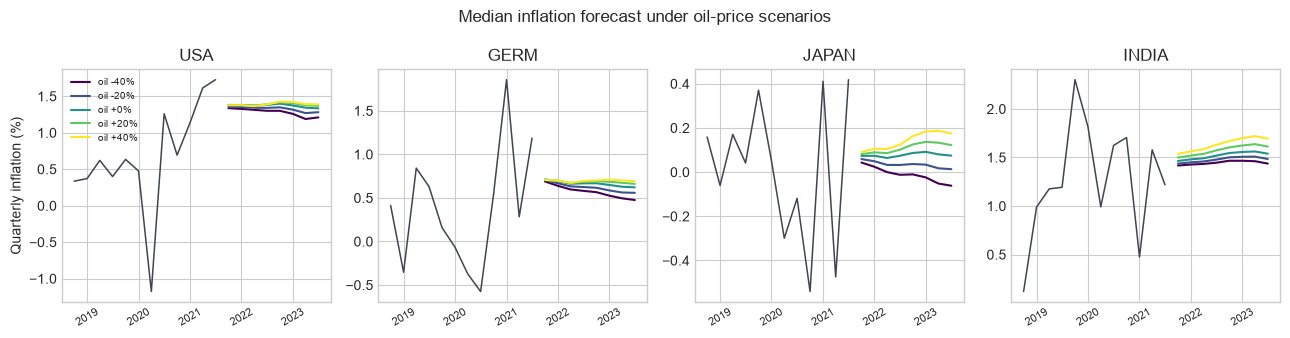

In [11]:
OIL_SHIFTS = [-0.4, -0.2, 0.0, 0.2, 0.4]
SCENARIO_COUNTRIES = ["usa", "germ", "japan", "india"]
scenario_origin = len(quarters) - QUARTERLY_HORIZON

def oil_scenario(row, shift):
    paths = {name: np.full(QUARTERLY_HORIZON, gvar[name][row, scenario_origin - 1], dtype=np.float32) for name in COMMODITIES}
    paths["poil"] = (gvar["poil"][row, scenario_origin - 1] + np.linspace(shift / QUARTERLY_HORIZON, shift, QUARTERLY_HORIZON)).astype(np.float32)
    return make_inflation_input(row, scenario_origin, "scenario", paths)

scenario_rows = [countries.index(c) for c in SCENARIO_COUNTRIES]
scenario_quantiles = predict([oil_scenario(row, s) for row in scenario_rows for s in OIL_SHIFTS], QUARTERLY_HORIZON).reshape(len(scenario_rows), len(OIL_SHIFTS), QUARTERLY_HORIZON, -1)

fig, axes = plt.subplots(1, len(scenario_rows), figsize=(13, 3.4), sharex=True)
cmap = plt.get_cmap("viridis")
for ax, row, quantiles in zip(axes, scenario_rows, scenario_quantiles):
    ax.plot(quarters[scenario_origin - 12:scenario_origin], 100 * gvar["Dp"][row, scenario_origin - 12:scenario_origin], color=COLORS["history"], lw=1.1)
    for k, (shift, q) in enumerate(zip(OIL_SHIFTS, quantiles)):
        ax.plot(quarters[scenario_origin:scenario_origin + QUARTERLY_HORIZON], 100 * q[:, 1], color=cmap(k / (len(OIL_SHIFTS) - 1)), lw=1.5, label=f"oil {shift:+.0%}")
    ax.set_title(countries[row].upper())
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
axes[0].set_ylabel("Quarterly inflation (%)")
axes[0].legend(frameon=False, fontsize=7, loc="upper left")
fig.suptitle("Median inflation forecast under oil-price scenarios", fontsize=12)
plt.tight_layout()
savefig(fig, "03_oil_scenarios")
plt.show()

### 3c. Dose–response: oil prices vs. inflation

x-axis: the oil-price change by the end of the horizon; y-axis: the change in average predicted quarterly inflation relative to the flat-oil scenario. Dashed lines: the response implied by a pass-through regression on each country's 15-year context, `Dp_t ~ Δpoil_t + Δpoil_{t-1}`. The model should slope upward like the regression; similar slopes mean its sensitivity is in a plausible range.

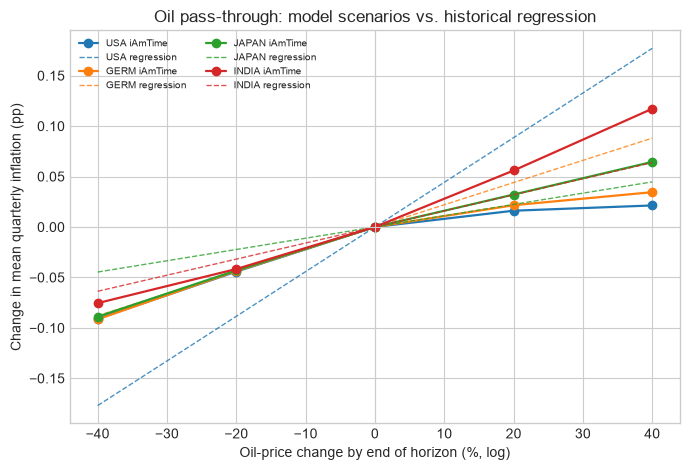

         iAmTime (pp per +40% oil)  regression (pp per +40% oil)
country                                                         
usa                          0.021                         0.177
germ                         0.034                         0.088
japan                        0.064                         0.045
india                        0.117                         0.064


In [12]:
fig, ax = plt.subplots(figsize=(7, 4.8))
rows_out = []
for k, (row, quantiles) in enumerate(zip(scenario_rows, scenario_quantiles)):
    flat_mean = quantiles[OIL_SHIFTS.index(0.0)][:, 1].mean()
    response = [100 * (q[:, 1].mean() - flat_mean) for q in quantiles]
    ctx = slice(scenario_origin - GVAR_CONTEXT, scenario_origin)
    d_oil = np.diff(gvar["poil"][row, ctx])
    design = np.column_stack([np.ones(len(d_oil) - 1), d_oil[1:], d_oil[:-1]])
    coefficients, *_ = np.linalg.lstsq(design, gvar["Dp"][row, ctx][2:], rcond=None)
    implied = [100 * (coefficients[1] + coefficients[2]) * s / QUARTERLY_HORIZON for s in OIL_SHIFTS]  # Steady per-quarter oil change.
    color = plt.get_cmap("tab10")(k)
    ax.plot([100 * s for s in OIL_SHIFTS], response, "o-", color=color, lw=1.6, label=f"{countries[row].upper()} iAmTime")
    ax.plot([100 * s for s in OIL_SHIFTS], implied, "--", color=color, lw=1.0, alpha=0.8, label=f"{countries[row].upper()} regression")
    rows_out.append({"country": countries[row], "iAmTime (pp per +40% oil)": response[-1], "regression (pp per +40% oil)": implied[-1]})
ax.axhline(0, color="#cccccc", lw=0.8)
ax.axvline(0, color="#cccccc", lw=0.8)
ax.set_xlabel("Oil-price change by end of horizon (%, log)")
ax.set_ylabel("Change in mean quarterly inflation (pp)")
ax.set_title("Oil pass-through: model scenarios vs. historical regression")
ax.legend(ncol=2, frameon=False, fontsize=7, loc="upper left")
plt.tight_layout()
savefig(fig, "03_dose_response")
plt.show()
print(pd.DataFrame(rows_out).set_index("country").round(3).to_string())

**Result.** For all four economies the model's inflation forecast rises monotonically with the assumed oil path: the pass-through has the right sign. Its size differs from the simple regression: smaller for the US and Germany, larger for Japan and India. The effects are small (at most about 0.1 percentage point of quarterly inflation for a 40 % oil rise) compared with the swings in the history. Without observed counterfactuals this is a plausibility check, not a validation.

## 4. Forecasting with examples: historical analogues for GDP

The full ICL input supplies completed **support examples** before the query. Each example has a target history and its observed future; the model treats them as demonstrations of how series like the query behave, without fine-tuning.

**Data.** `gvar` log real GDP (`y`) for 33 countries, quarterly.

**Input card.**

```python
{
    "example_target_histories": [hist_1, ..., hist_k],   # each (20,)  completed demonstrations
    "example_target_futures":   [fut_1,  ..., fut_k],    # each (8,)
    "query_target_history":     hist_q,                  # (20,)       the series to forecast
}
```

**Design: analogue examples.** The query sees its last **20 quarters** (5 years). Candidate examples are all 20 + 8-quarter windows of GDP, from **any** country, whose 8-quarter future ends before the query's forecast origin (no leakage). Each window's history is z-normalised (shape, not level or growth rate) and compared with the query's; the closest windows are the examples, with at most one per country within any 8-quarter span. This is analogue forecasting: "the last time an economy looked like this, what happened next?"

| § | Question | Format |
|---|---|---|
| 4a | What does one forecast look like? | a query and its analogues |
| 4b | What does the model actually see? | prompt-anatomy figure |
| 4c | Do analogues help, and which ones? | scorecard on 256 forecasts + ladder with random windows and a shuffled-futures **control**; the same test on inflation |
| 4d | How does the error change with the number of examples? | k-shot curve, k = 0 to 12 |
| 4e | Cold start | a country with only 8 quarters of history |

In [13]:
ICL_CONTEXT = 20

def z_normalise(window):
    return (window - window.mean()) / max(window.std(), 1e-9)

def candidate_windows(series, origin, context, rows=None):
    rows = range(series.shape[0]) if rows is None else rows
    return [(r, e) for r in rows for e in range(context, origin - QUARTERLY_HORIZON + 1)]

def analogues(series, row, origin, count, context=ICL_CONTEXT, rows=None):
    candidates = candidate_windows(series, origin, context, rows)
    windows = np.stack([z_normalise(series[r, e - context:e]) for r, e in candidates])
    distances = np.linalg.norm(windows - z_normalise(series[row, origin - context:origin]), axis=1)
    chosen = []
    for k in np.argsort(distances):
        r, e = candidates[k]
        if all(not (r == r2 and abs(e - e2) < QUARTERLY_HORIZON) for r2, e2 in chosen):
            chosen.append((r, e))
        if len(chosen) == count:
            break
    return chosen

def random_windows(series, row, origin, count, context=ICL_CONTEXT):
    candidates = candidate_windows(series, origin, context)
    picks = np.random.default_rng(1000 * row + origin).choice(len(candidates), size=count, replace=False)
    return [candidates[k] for k in picks]

def make_example_input(series, row, origin, sources, context=ICL_CONTEXT, shuffle_futures=False):
    query = series[row, origin - context:origin]
    if not sources:
        return {"query_target_history": query}
    futures = [series[r, e:e + QUARTERLY_HORIZON] for r, e in sources]
    if shuffle_futures:
        futures = futures[1:] + futures[:1]  # Every history gets another example's future.
    return {
        "example_target_histories": [series[r, e - context:e] for r, e in sources],
        "example_target_futures": futures,
        "query_target_history": query,
    }

def score(series, row, origin, forecast, context=ICL_CONTEXT):
    return mase(series[row, origin - context:origin], series[row, origin:origin + QUARTERLY_HORIZON], forecast, 1)

gdp = gvar["y"]

### 4a. One query and its analogues

The query is US GDP from 2011Q1, about 18 months into the recovery from the 2008–2009 recession; its 20-quarter context (2006–2010) contains the whole recession. The 10 closest analogues come from all countries' history with futures ending before 2011Q1: other economies a few years after a downturn. The query was picked from the evaluation queries as one where analogues help clearly; 4c shows the typical effect. Analogues cannot anticipate a shock that no past window resembles: for Germany from 2008Q3, at the start of the financial crisis, the forecast with analogues is worse than without.

Analogues: per 1985Q2, can 1993Q2, chl 1984Q3, indns 2000Q3, thai 2000Q2, arg 1987Q1, uk 1993Q3, japan 2000Q3, mex 1997Q2, japan 1996Q1


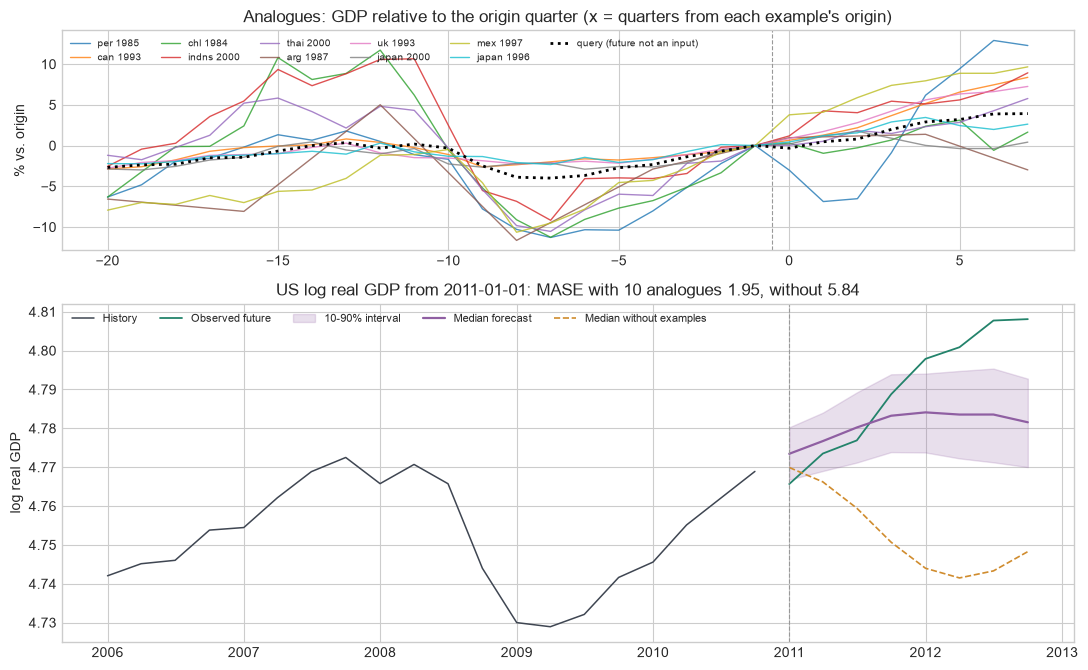

In [14]:
HERO_COUNTRY = "usa"
HERO_ORIGIN = pd.Timestamp("2011-01-01")
NUM_ANALOGUES = 10

hero_row = countries.index(HERO_COUNTRY)
hero_origin = int(np.flatnonzero(quarters == HERO_ORIGIN)[0])
hero_sources = analogues(gdp, hero_row, hero_origin, NUM_ANALOGUES)
print("Analogues:", ", ".join(f"{countries[r]} {quarters[e].year}Q{quarters[e].quarter}" for r, e in hero_sources))
example_q, zero_q = predict([make_example_input(gdp, hero_row, hero_origin, hero_sources), make_example_input(gdp, hero_row, hero_origin, [])], QUARTERLY_HORIZON)
hero_context = gdp[hero_row, hero_origin - ICL_CONTEXT:hero_origin]
hero_truth = gdp[hero_row, hero_origin:hero_origin + QUARTERLY_HORIZON]
future_quarters = quarters[hero_origin:hero_origin + QUARTERLY_HORIZON]

fig, axes = plt.subplots(2, 1, figsize=(11, 6.8), gridspec_kw={"height_ratios": [1.3, 2.0]})
for r, e in hero_sources:
    window = gdp[r, e - ICL_CONTEXT:e + QUARTERLY_HORIZON]
    axes[0].plot(np.arange(-ICL_CONTEXT, QUARTERLY_HORIZON), 100 * (window - window[ICL_CONTEXT - 1]), lw=1.0, alpha=0.8, label=f"{countries[r]} {quarters[e].year}")
query_window = gdp[hero_row, hero_origin - ICL_CONTEXT:hero_origin + QUARTERLY_HORIZON]
axes[0].plot(np.arange(-ICL_CONTEXT, QUARTERLY_HORIZON), 100 * (query_window - query_window[ICL_CONTEXT - 1]), color="black", lw=2.0, ls=":", label="query (future not an input)")
axes[0].axvline(-0.5, color="#999999", lw=0.8, ls="--")
axes[0].set_title("Analogues: GDP relative to the origin quarter (x = quarters from each example's origin)")
axes[0].set_ylabel("% vs. origin")
axes[0].legend(ncol=6, frameon=False, loc="upper left", fontsize=7)

plot_forecast(axes[1], quarters[hero_origin - ICL_CONTEXT:hero_origin], hero_context, future_quarters, hero_truth, example_q,
              f"US log real GDP from {HERO_ORIGIN.date()}: MASE with {NUM_ANALOGUES} analogues {score(gdp, hero_row, hero_origin, example_q[:, 1]):.2f}, "
              f"without {score(gdp, hero_row, hero_origin, zero_q[:, 1]):.2f}",
              reference=zero_q[:, 1], reference_label="Median without examples", ylabel="log real GDP")
axes[1].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "04a_analogues")
plt.show()

### 4b. Prompt anatomy: what the model actually sees

The first five analogues of 4a and the query, drawn the way the model receives them: completed examples (history → observed future), then the query (history → **?**). The x-axis is quarters from each block's forecast origin.

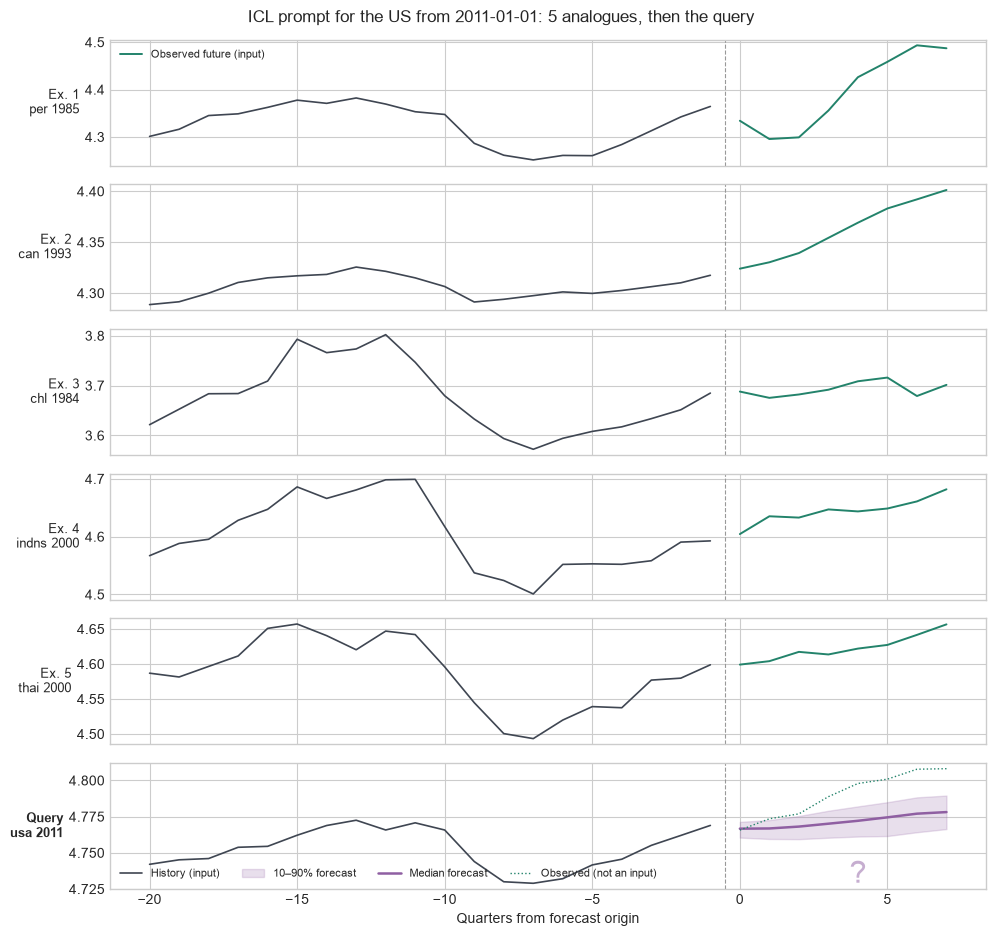

In [15]:
def plot_prompt_anatomy(series, row, origin, sources, quantiles, title, name=None, context=ICL_CONTEXT, ylabel="log real GDP"):
    rows = len(sources) + 1
    fig, axes = plt.subplots(rows, 1, figsize=(10, 1.45 * rows + 0.8), sharex=True)
    future_x = np.arange(0, QUARTERLY_HORIZON)
    for k, (ax, (r, e)) in enumerate(zip(axes, sources)):
        ax.plot(np.arange(-context, 0), series[r, e - context:e], color=COLORS["history"], lw=1.2)
        ax.plot(future_x, series[r, e:e + QUARTERLY_HORIZON], color=COLORS["truth"], lw=1.4)
        ax.set_ylabel(f"Ex. {k + 1}\n{countries[r]} {quarters[e].year}", rotation=0, ha="right", va="center", fontsize=9)
    ax = axes[-1]
    ax.plot(np.arange(-context, 0), series[row, origin - context:origin], color=COLORS["history"], lw=1.2, label="History (input)")
    ax.fill_between(future_x, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.2, label="10–90% forecast")
    ax.plot(future_x, quantiles[:, 1], color=COLORS["forecast"], lw=1.8, label="Median forecast")
    ax.plot(future_x, series[row, origin:origin + QUARTERLY_HORIZON], color=COLORS["truth"], lw=1.0, ls=":", label="Observed (not an input)")
    ax.set_ylabel(f"Query\n{countries[row]} {quarters[origin].year}", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    ax.text(QUARTERLY_HORIZON / 2, 0.05, "?", transform=ax.get_xaxis_transform(), ha="center", fontsize=22, color=COLORS["forecast"], alpha=0.5)
    ax.legend(ncol=4, frameon=False, loc="lower left", fontsize=8)
    ax.set_xlabel("Quarters from forecast origin")
    for ax in axes:
        ax.axvline(-0.5, color="#999999", lw=0.8, ls="--")
    axes[0].plot([], [], color=COLORS["truth"], lw=1.4, label="Observed future (input)")
    axes[0].legend(frameon=False, loc="upper left", fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

anatomy_sources = hero_sources[:5]
anatomy_q = predict([make_example_input(gdp, hero_row, hero_origin, anatomy_sources)], QUARTERLY_HORIZON)[0]
plot_prompt_anatomy(gdp, hero_row, hero_origin, anatomy_sources, anatomy_q,
                    f"ICL prompt for the US from {HERO_ORIGIN.date()}: 5 analogues, then the query", name="04b_prompt_anatomy")

### 4c. Scorecard: do analogues help, and which ones?

256 random (country, origin) forecasts with yearly origins from 1999 to 2021, so every query has at least 20 years of candidate history. Variants:

- zero-shot from the same 20 quarters (the **reference**),
- 5 analogues from the query country's own past only,
- 5 analogues from any country,
- 10 analogues from any country,
- 5 **random** windows from any country (same amount of data, no similarity),
- **control**: the 5 analogues with their futures rotated, so every history is paired with another example's future. If this control were as good as the real analogues, the benefit would be "more context", not in-context learning.

The second table runs the main variants on **inflation** (`Dp`) with the same design, as a check of whether the result carries over to another variable.

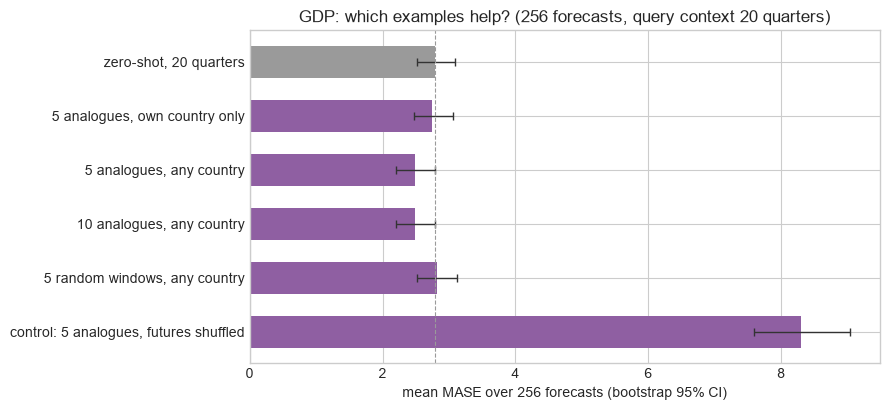

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 20 quarters",,,,,,
"zero-shot, 20 quarters",2.790,"[2.515, 3.092]",2.130,NaN,0.000,"[0.000, 0.000]"
"5 analogues, own country only",2.750,"[2.470, 3.056]",2.000,0.480,-0.040,"[-0.234, 0.159]"
"5 analogues, any country",2.486,"[2.201, 2.797]",1.743,0.562,-0.304,"[-0.476, -0.134]"
"10 analogues, any country",2.487,"[2.196, 2.786]",1.713,0.559,-0.303,"[-0.467, -0.136]"
"5 random windows, any country",2.814,"[2.516, 3.118]",1.798,0.484,0.024,"[-0.176, 0.227]"
"control: 5 analogues, futures shuffled",8.303,"[7.589, 9.034]",7.293,0.152,5.513,"[4.807, 6.263]"


In [16]:
rng = np.random.default_rng(0)
eval_origins = [int(np.flatnonzero(quarters == pd.Timestamp(f"{year}-01-01"))[0]) for year in range(1999, 2022)]
all_pairs = [(row, o) for row in range(len(countries)) for o in eval_origins]
eval_pairs = [all_pairs[k] for k in rng.choice(len(all_pairs), size=256, replace=False)]

def run_variants(series, variants):
    return pd.DataFrame({
        name: [score(series, r, o, q[:, 1]) for (r, o), q in zip(eval_pairs, predict([build(r, o) for r, o in eval_pairs], QUARTERLY_HORIZON))]
        for name, build in variants.items()
    })

own_rows = lambda r: [r]
gdp_results = run_variants(gdp, {
    "zero-shot, 20 quarters": lambda r, o: make_example_input(gdp, r, o, []),
    "5 analogues, own country only": lambda r, o: make_example_input(gdp, r, o, analogues(gdp, r, o, 5, rows=own_rows(r))),
    "5 analogues, any country": lambda r, o: make_example_input(gdp, r, o, analogues(gdp, r, o, 5)),
    "10 analogues, any country": lambda r, o: make_example_input(gdp, r, o, analogues(gdp, r, o, 10)),
    "5 random windows, any country": lambda r, o: make_example_input(gdp, r, o, random_windows(gdp, r, o, 5)),
    "control: 5 analogues, futures shuffled": lambda r, o: make_example_input(gdp, r, o, analogues(gdp, r, o, 5), shuffle_futures=True),
})
REFERENCE = "zero-shot, 20 quarters"
plot_ladder(gdp_results, REFERENCE, f"GDP: which examples help? ({len(gdp_results)} forecasts, query context 20 quarters)", name="04c_relevance_ladder")
scorecard(gdp_results, reference=REFERENCE)

**Result (GDP).** Analogues from **any** country help: mean MASE 2.49 vs 2.79 and median 1.74 vs 2.13, with the CI on the difference excluding 0; 5 and 10 analogues perform the same. Analogues from the query country's own past only, and random windows, do not help: what matters is having many similar situations to draw from. The **shuffled-futures control is catastrophic** (mean MASE 8.3): the model reads the history → future pairing, so wrong demonstrations actively mislead it.

In [17]:
inflation = gvar["Dp"]
inflation_results = run_variants(inflation, {
    "zero-shot, 20 quarters": lambda r, o: make_example_input(inflation, r, o, []),
    "5 analogues, any country": lambda r, o: make_example_input(inflation, r, o, analogues(inflation, r, o, 5)),
    "10 analogues, any country": lambda r, o: make_example_input(inflation, r, o, analogues(inflation, r, o, 10)),
    "5 random windows, any country": lambda r, o: make_example_input(inflation, r, o, random_windows(inflation, r, o, 5)),
})
scorecard(inflation_results, reference=REFERENCE)

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 20 quarters",,,,,,
"zero-shot, 20 quarters",1.282,"[1.163, 1.407]",0.981,NaN,0.000,"[0.000, 0.000]"
"5 analogues, any country",1.573,"[1.431, 1.714]",1.253,0.250,0.291,"[0.215, 0.378]"
"10 analogues, any country",1.488,"[1.352, 1.626]",1.152,0.309,0.206,"[0.145, 0.268]"
"5 random windows, any country",1.400,"[1.278, 1.525]",1.071,0.414,0.117,"[0.052, 0.188]"


**Result (inflation).** The same design **hurts** inflation forecasts (mean MASE 1.49–1.57 vs 1.28 for analogues), and random windows hurt less than analogues. Quarterly inflation is noisy and mean-reverting, so matching the shape of the last 20 quarters mostly matches noise, and the selected windows' futures mislead. Analogue examples suit smooth, persistent series like GDP, not every macro variable.

### 4d. Error vs. number of examples

The k-shot curve for GDP on the same 256 forecasts: the `k` closest analogues from any country, for `k = 0, 1, 2, 3, 5, 8, 10, 12`. The checkpoint was trained with up to 6 examples; the shaded region (`k > 6`) is beyond that, and the model accepts it without changes.

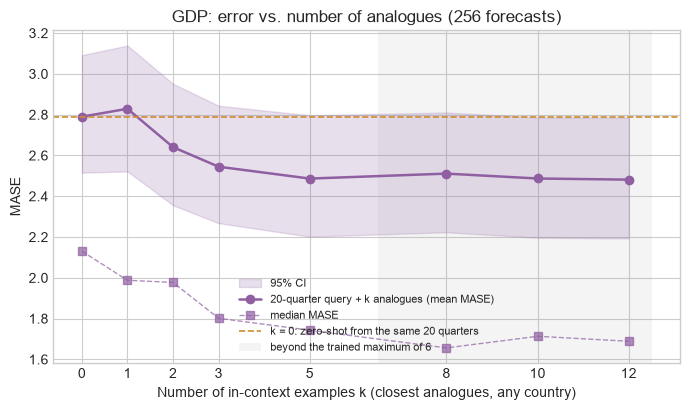

         k=0    k=1    k=2    k=3    k=5    k=8   k=10   k=12
mean    2.79  2.829  2.640  2.545  2.486  2.511  2.487  2.481
median  2.13  1.988  1.977  1.801  1.743  1.656  1.713  1.689


In [18]:
EXAMPLE_COUNTS = [0, 1, 2, 3, 5, 8, 10, 12]
TRAINED_MAX_EXAMPLES = 6

curve_scores = run_variants(gdp, {f"k={k}": (lambda k: lambda r, o: make_example_input(gdp, r, o, analogues(gdp, r, o, k) if k else []))(k) for k in EXAMPLE_COUNTS})
rng = np.random.default_rng(0)
idx = rng.integers(0, len(curve_scores), size=(2000, len(curve_scores)))
curve_mean = curve_scores.mean()
curve_ci = np.stack([np.percentile(curve_scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in curve_scores.columns])

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.fill_between(EXAMPLE_COUNTS, curve_ci[:, 0], curve_ci[:, 1], color=COLORS["forecast"], alpha=0.2, label="95% CI")
ax.plot(EXAMPLE_COUNTS, curve_mean, "o-", color=COLORS["forecast"], lw=1.8, label="20-quarter query + k analogues (mean MASE)")
ax.plot(EXAMPLE_COUNTS, curve_scores.median(), "s--", color=COLORS["forecast"], lw=1.0, alpha=0.7, label="median MASE")
ax.axhline(curve_mean.iloc[0], color=COLORS["reference"], lw=1.2, ls="--", label="k = 0: zero-shot from the same 20 quarters")
ax.axvspan(TRAINED_MAX_EXAMPLES + 0.5, EXAMPLE_COUNTS[-1] + 0.5, color="#999999", alpha=0.10, lw=0, label="beyond the trained maximum of 6")
ax.set_xticks(EXAMPLE_COUNTS)
ax.set_xlabel("Number of in-context examples k (closest analogues, any country)")
ax.set_ylabel("MASE")
ax.set_title(f"GDP: error vs. number of analogues ({len(curve_scores)} forecasts)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
savefig(fig, "04d_example_count_curve")
plt.show()
print(pd.DataFrame({"mean": curve_mean, "median": curve_scores.median()}).round(3).T.to_string())

**Result.** One analogue is not enough (slightly worse than zero-shot), but the error falls steadily up to about 5 analogues and is flat after that; the median keeps improving a little up to 8. Going beyond the trained maximum of 6 neither helps nor breaks the model.

### 4e. Cold start: a country with 8 quarters of history

A country whose statistics were recently rebased, or a new economic region, may have only two years of comparable data. Can analogues from other countries stand in for the missing history?

- **Query**: the last `COLD_CONTEXT = 8` quarters of GDP.
- **Examples**: the 5 closest 8 + 8-quarter windows from **other** countries (the query country's own past is not used).

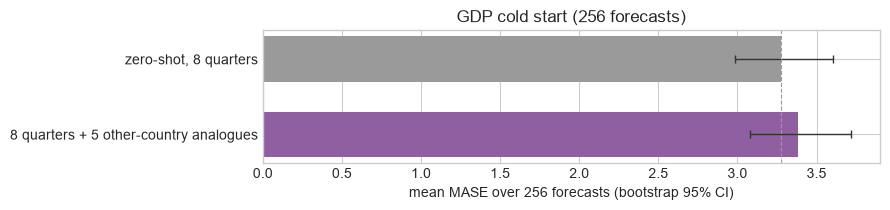

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 8 quarters",,,,,,
"zero-shot, 8 quarters",3.277,"[2.983, 3.603]",2.584,NaN,0.000,"[0.000, 0.000]"
8 quarters + 5 other-country analogues,3.385,"[3.080, 3.715]",2.692,0.484,0.108,"[-0.139, 0.347]"


In [19]:
COLD_CONTEXT = 8
other_rows = lambda r: [x for x in range(len(countries)) if x != r]

cold_variants = {
    "zero-shot, 8 quarters": lambda r, o: make_example_input(gdp, r, o, [], context=COLD_CONTEXT),
    "8 quarters + 5 other-country analogues": lambda r, o: make_example_input(gdp, r, o, analogues(gdp, r, o, 5, context=COLD_CONTEXT, rows=other_rows(r)), context=COLD_CONTEXT),
}
cold_results = pd.DataFrame({  # MASE scaled on the 8-quarter context the query actually has.
    name: [score(gdp, r, o, q[:, 1], context=COLD_CONTEXT) for (r, o), q in zip(eval_pairs, predict([build(r, o) for r, o in eval_pairs], QUARTERLY_HORIZON))]
    for name, build in cold_variants.items()
})
plot_ladder(cold_results, "zero-shot, 8 quarters", f"GDP cold start ({len(cold_results)} forecasts)", name="04e_cold_start_ladder")
scorecard(cold_results, reference="zero-shot, 8 quarters")

**Result.** With only 8 quarters of history, analogues from other countries do not help (the CI on the difference includes 0, win rate 48 %). Two years of GDP are too short to identify which past situations are similar, so the selected analogues are close to random. Unlike the energy cold start, where the calendar told us which windows to use, the analogue approach needs enough query history to match on.

## Summary

| § | What was shown | Reference |
|---|---|---|
| 1 | Zero-shot 12-month forecasts of US consumer spending | random walk with drift |
| 2 | Joint forecast of payrolls, CPI and the federal funds rate | each variable alone |
| 3 | Inflation with past commodity prices; oil-price scenarios and a pass-through dose–response | without covariates; historical regression |
| 4 | Historical analogues as examples for GDP; random-window and shuffled-futures controls; k-shot curve; cold start; the same test on inflation | zero-shot from the same short context |

Takeaways on this data: zero-shot forecasts beat the random walk with drift on consumer spending; joint forecasting of the CEE variables gives no reliable gain; past commodity prices add nothing to inflation forecasts, but their future paths matter, so scenarios are the useful way to use them; and analogue examples from many countries improve short-context GDP forecasts, while the same approach hurts inflation and fails with only 8 quarters of history.

Covariates are not passed inside examples: in the Walmart demo, doing so made the model ignore the query's own covariates, and that behaviour is not yet understood.

## Checkpoint scope

This notebook uses the publicly available forecasting checkpoint. iAmTime also supports imputation, anomaly detection, and classification, but checkpoints for those tasks are not currently published.